# Model Comparison: Advanced Algorithms

In this notebook, we move beyond the Logistic Regression baseline and evaluate tree-based algorithms. 

We will test:
1. **Decision Tree**: Simple, fast, but prone to overfitting.
2. **Random Forest**: An ensemble method that reduces overfitting.
3. **XGBoost**: The state-of-the-art for tabular data, usually offering the best balance of speed and performance.

*Note: Support Vector Machines (SVM) scale poorly ($O(N^2)$ to $O(N^3)$) and are computationally infeasible on a dataset with 6.3 million rows without aggressive subsampling, so we exclude it here in favor of XGBoost.*

In [1]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
import sys
sys.path.append('..')

from src.preprocessing import load_and_clean_data, preprocess_and_split
from src.feature_engineering import engineer_features
from src.evaluate import evaluate_model

### 1. Load Data
*(Loading 6.3M rows takes a bit of time)*

In [2]:
data_path = '../data/raw/PS_20174392719_1491204439457_log.csv'
df = load_and_clean_data(data_path)
X_train, X_val, X_test, y_train, y_val, y_test, preprocessor = preprocess_and_split(df, val_size=0.15, test_size=0.15, random_state=42)
print("Data ready!")

Data ready!


### 2. Decision Tree
We use `class_weight='balanced'` to penalize minority class misclassifications.

Training Decision Tree...


--- Evaluation for Decision Tree ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    414330
           1       0.96      1.00      0.98      1232

    accuracy                           1.00    415562
   macro avg       0.98      1.00      0.99    415562
weighted avg       1.00      1.00      1.00    415562



ROC-AUC: 0.9976
PR-AUC:  0.9927


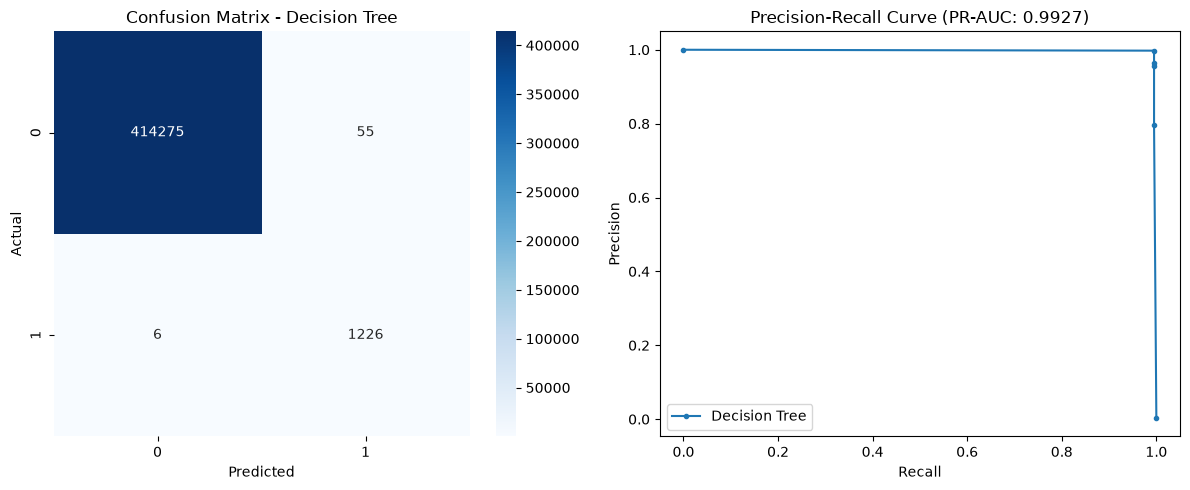

In [3]:
dt = DecisionTreeClassifier(class_weight='balanced', max_depth=10, random_state=42)
print("Training Decision Tree...")
dt.fit(X_train, y_train)
metrics_dt = evaluate_model(y_val, dt.predict(X_val), dt.predict_proba(X_val)[:, 1], "Decision Tree")

### 3. Random Forest
To save time on this huge dataset, we limit `n_estimators=50` and `max_depth=10`. We also use `n_jobs=-1` to use all CPU cores.

Training Random Forest...


--- Evaluation for Random Forest ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    414330
           1       0.98      1.00      0.99      1232

    accuracy                           1.00    415562
   macro avg       0.99      1.00      0.99    415562
weighted avg       1.00      1.00      1.00    415562



ROC-AUC: 0.9992
PR-AUC:  0.9960


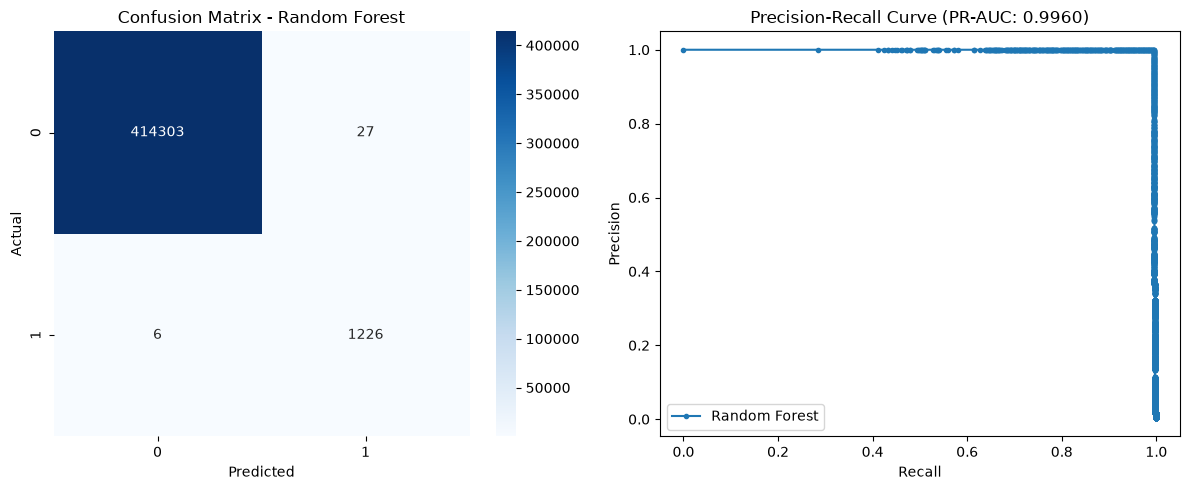

In [4]:
rf = RandomForestClassifier(class_weight='balanced', n_estimators=50, max_depth=10, n_jobs=-1, random_state=42)
print("Training Random Forest...")
rf.fit(X_train, y_train)
metrics_rf = evaluate_model(y_val, rf.predict(X_val), rf.predict_proba(X_val)[:, 1], "Random Forest")

### 4. XGBoost
XGBoost requires a different parameter `scale_pos_weight` to handle class imbalance instead of `class_weight`.
We use `tree_method='hist'` which uses histogram binning to drastically speed up training on large datasets.

Training XGBoost...


--- Evaluation for XGBoost ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    414330
           1       0.98      0.99      0.99      1232

    accuracy                           1.00    415562
   macro avg       0.99      1.00      0.99    415562
weighted avg       1.00      1.00      1.00    415562



ROC-AUC: 0.9994
PR-AUC:  0.9948


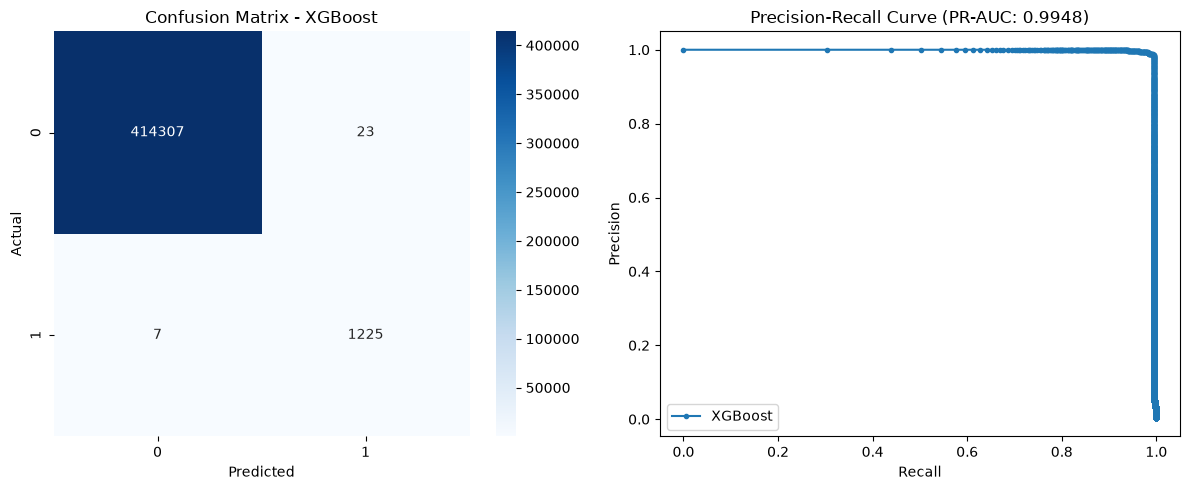

In [5]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
xgb_model = xgb.XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    tree_method='hist',
    max_depth=6,
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
print("Training XGBoost...")
xgb_model.fit(X_train, y_train)
metrics_xgb = evaluate_model(y_val, xgb_model.predict(X_val), xgb_model.predict_proba(X_val)[:, 1], "XGBoost")

### 5. Support Vector Machine (Approximated)
Standard SVM scales poorly. We use SGDClassifier with modified_huber loss as a scalable proxy.

Training SVM (SGD Approximation)...


--- Evaluation for SVM (SGD) ---
              precision    recall  f1-score   support

           0       1.00      0.89      0.94    414330
           1       0.02      0.89      0.05      1232

    accuracy                           0.89    415562
   macro avg       0.51      0.89      0.50    415562
weighted avg       1.00      0.89      0.94    415562



ROC-AUC: 0.9112
PR-AUC:  0.0246


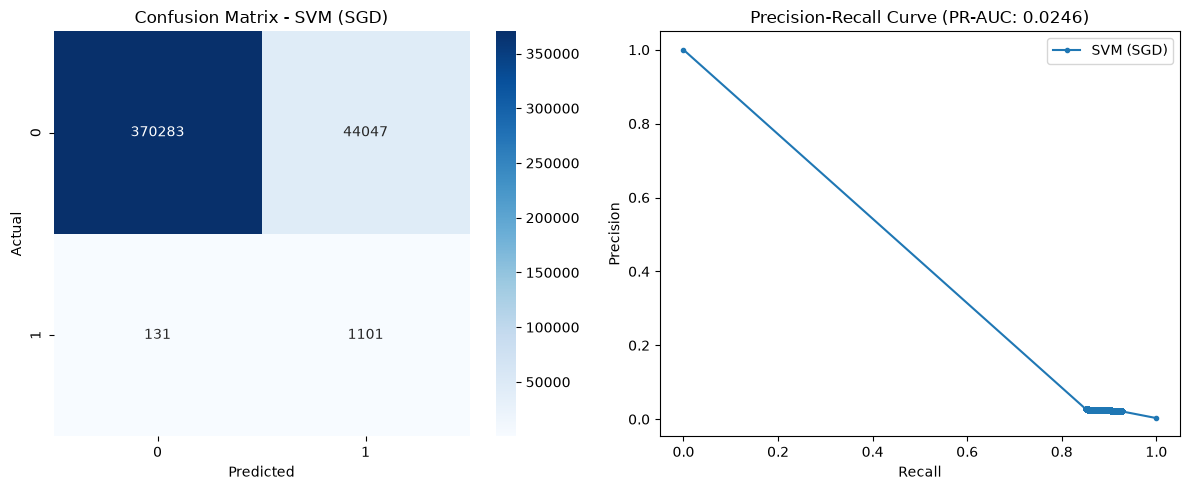

In [6]:
from sklearn.linear_model import SGDClassifier
svm_model = SGDClassifier(loss='modified_huber', class_weight='balanced', max_iter=1000, random_state=42, n_jobs=-1)
print("Training SVM (SGD Approximation)...")
svm_model.fit(X_train, y_train)
metrics_svm = evaluate_model(y_val, svm_model.predict(X_val), svm_model.predict_proba(X_val)[:, 1], "SVM (SGD)")

In [7]:
import json
results = {
    'Decision Tree': metrics_dt,
    'Random Forest': metrics_rf,
    'SVM': metrics_svm,
    'XGBoost': metrics_xgb
}
with open('../reports/model_comparison.json', 'w') as f:
    json.dump(results, f, indent=4)
print("Saved comparison metrics.")

Saved comparison metrics.
